# Superstore Sales and Profitability Analysis

## Project Overview

This project analyzes Superstore sales data to understand sales performance, profitability, customer behavior, product performance, regional performance, discounting, and shipping efficiency.

The analysis uses Python, Pandas, NumPy, Matplotlib, and Seaborn for data cleaning, exploratory data analysis, visualization, and business insights.

In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

In [123]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7


# 1. Business Problem

The objective of this project is to analyze Superstore sales data and identify factors affecting sales and profitability.

### Key Business Questions

- Which categories and sub-categories generate the highest sales and profit?
- Which products generate high sales but low or negative profit?
- How does discounting affect profitability?
- Which regions and customer segments perform best?
- How do sales and profit change over time?
- Which shipping methods provide the best performance?
- Which customers generate high revenue but low or negative profit?

# 2. Dataset Overview

The dataset contains sales transaction records from a Superstore business.

### Dataset Characteristics

- **9,994** transaction records
- **21** columns
- Sales, quantity, discount, and profit information
- Customer and product information
- Geographic information such as city, state, and region
- Order and shipping dates
- Different shipping modes and customer segments

The dataset contains both numerical and categorical variables, making it suitable for exploratory data analysis and business performance analysis.


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [12]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [14]:
df.describe(include="object")

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994
unique,5009,1237,1334,4,793,793,3,1,531,49,4,1862,3,17,1850
top,CA-2017-100111,9/5/2016,12/16/2015,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,38,35,5968,37,37,5191,9994,915,2001,3203,19,6026,1523,48


# 3. Data Cleaning

The dataset was checked for duplicate records, missing values, incorrect data types, and inconsistent categorical values.

### Data Cleaning Steps

- Checked for duplicate rows
- Checked for missing values
- Converted Order Date and Ship Date to datetime format
- Checked categorical values for consistency
- Checked numerical columns for invalid negative values
- Created a Shipping Days variable from the order and ship dates

No exact duplicate rows or missing values were found. Repeated Order IDs, Customer IDs, and Product IDs were retained because they represent legitimate multiple transactions, products, or purchases.

In [16]:
df.duplicated().sum()

0

In [18]:
df["Order ID"].duplicated().sum()

4985

In [20]:
print("Duplicate Order IDs:", df["Order ID"].duplicated().sum())
print("Duplicate Customer IDs:", df["Customer ID"].duplicated().sum())
print("Duplicate Product IDs:", df["Product ID"].duplicated().sum())

Duplicate Order IDs: 4985
Duplicate Customer IDs: 9201
Duplicate Product IDs: 8132


In [22]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [24]:
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

In [26]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [28]:
df.isnull().sum().sum()

0

In [30]:
print("Ship Modes:")
print(df["Ship Mode"].unique())

Ship Modes:
['Second Class' 'Standard Class' 'First Class' 'Same Day']


In [32]:
print("Segments:")
print(df["Segment"].unique())

Segments:
['Consumer' 'Corporate' 'Home Office']


In [34]:
print("Categories:")
print(df["Category"].unique())

Categories:
['Furniture' 'Office Supplies' 'Technology']


In [36]:
print("Regions:")
print(df["Region"].unique())

Regions:
['South' 'West' 'Central' 'East']


In [38]:
print("Sub-Categories:")
print(df["Sub-Category"].unique())

Sub-Categories:
['Bookcases' 'Chairs' 'Labels' 'Tables' 'Storage' 'Furnishings' 'Art'
 'Phones' 'Binders' 'Appliances' 'Paper' 'Accessories' 'Envelopes'
 'Fasteners' 'Supplies' 'Machines' 'Copiers']


In [40]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [42]:
print("Negative Sales:", (df["Sales"] < 0).sum())
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Negative Discount:", (df["Discount"] < 0).sum())
print("Negative Profit:", (df["Profit"] < 0).sum())

Negative Sales: 0
Negative Quantity: 0
Negative Discount: 0
Negative Profit: 1871


In [44]:
df.groupby("Order ID")["Product ID"].nunique().describe()

count    5009.000000
mean        1.993611
std         1.408823
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        14.000000
Name: Product ID, dtype: float64

In [46]:
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

df["Shipping Days"].describe()

count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping Days, dtype: float64

# 4. Key Performance Indicators (KPIs)

The following key performance indicators are calculated to establish an overall view of business performance.

- Total Sales
- Total Profit
- Total Orders
- Total Customers
- Overall Profit Margin

In [48]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793


In [50]:
profit_margin = (total_profit / total_sales) * 100

print("Overall Profit Margin:", round(profit_margin, 2), "%")

Overall Profit Margin: 12.47 %


# 5. Category Analysis

In [52]:
category_analysis = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).sort_values("Sales", ascending=False)

category_analysis

,Sales,Profit,Orders
Category,,,
Technology,836154.0330,145454.9481,1544
Furniture,741999.7953,18451.2728,1764
Office Supplies,719047.0320,122490.8008,3742


In [54]:
category_analysis["Profit Margin (%)"] = (
    category_analysis["Profit"] / category_analysis["Sales"] * 100
).round(2)

category_analysis

,Sales,Profit,Orders,Profit Margin (%)
Category,,,,
Technology,836154.0330,145454.9481,1544,17.40
Furniture,741999.7953,18451.2728,1764,2.49
Office Supplies,719047.0320,122490.8008,3742,17.04


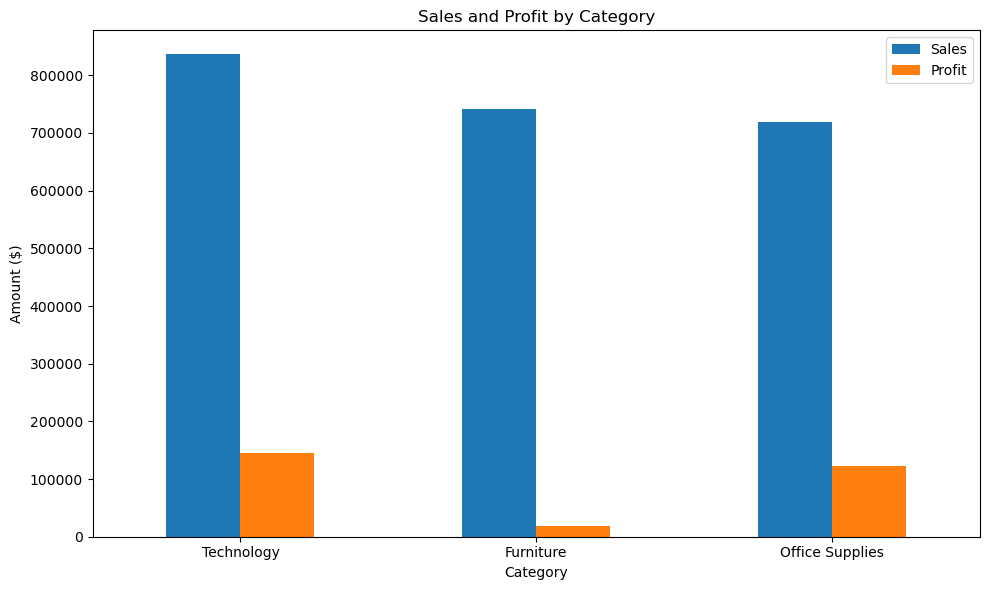

In [56]:
category_analysis[["Sales", "Profit"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 6. Sub-Category Analysis

In [58]:
subcategory_analysis = df.groupby("Sub-Category").agg(`
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).sort_values("Profit", ascending=False)

subcategory_analysis["Profit Margin (%)"] = (
    subcategory_analysis["Profit"] /
    subcategory_analysis["Sales"] * 100
).round(2)

subcategory_analysis

,Sales,Profit,Orders,Profit Margin (%)
Sub-Category,,,,
Copiers,149528.0300,55617.8249,68,37.20
Phones,330007.0540,44515.7306,814,13.49
Accessories,167380.3180,41936.6357,718,25.05
Paper,78479.2060,34053.5693,1191,43.39
Binders,203412.7330,30221.7633,1316,14.86
Chairs,328449.1030,26590.1663,576,8.10
Storage,223843.6080,21278.8264,777,9.51
Appliances,107532.1610,18138.0054,451,16.87
Furnishings,91705.1640,13059.1436,877,14.24


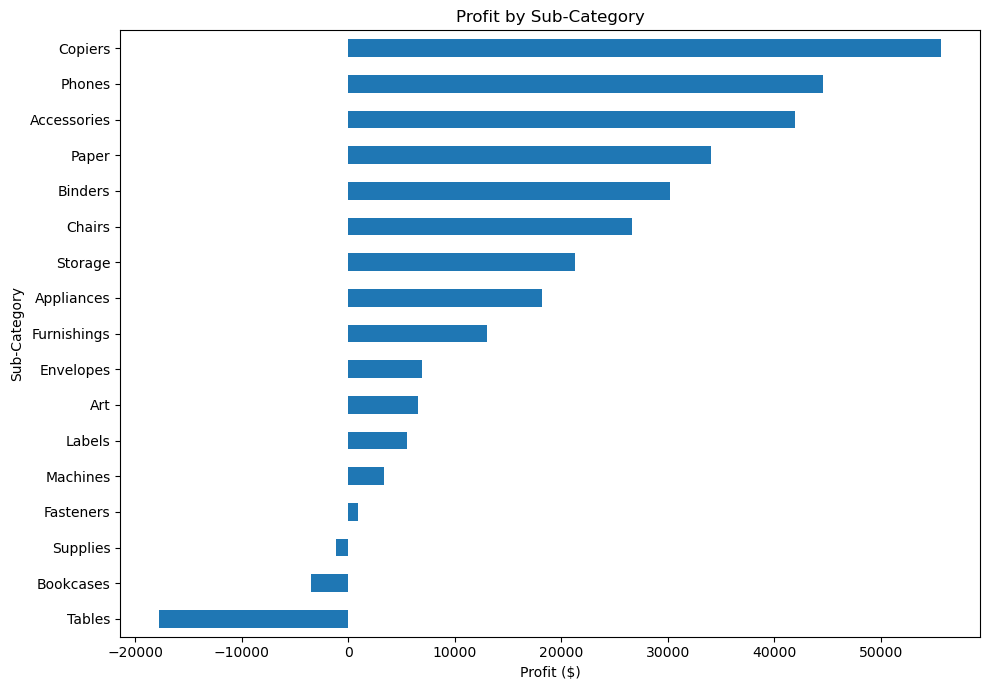

In [60]:
subcategory_analysis["Profit"].sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Profit by Sub-Category")
plt.xlabel("Profit ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

# 7. Discount and Profitability Analysis

In [62]:
discount_analysis = df.groupby("Discount").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)

discount_analysis["Profit Margin (%)"] = (
    discount_analysis["Profit"] / discount_analysis["Sales"] * 100
).round(2)

discount_analysis

,Sales,Profit,Orders,Profit Margin (%)
Discount,,,,
0.00,1.087908e+06,320987.6032,2644,29.51
0.10,5.436935e+04,9029.1770,89,16.61
0.15,2.755852e+04,1418.9915,51,5.15
0.20,7.645944e+05,90337.3060,2407,11.82
0.30,1.032267e+05,-10369.2774,211,-10.05
0.32,1.449346e+04,-2391.1377,27,-16.50
0.40,1.164178e+05,-23057.0504,185,-19.81
0.45,5.484974e+03,-2493.1111,10,-45.45
0.50,5.891854e+04,-20506.4281,64,-34.80


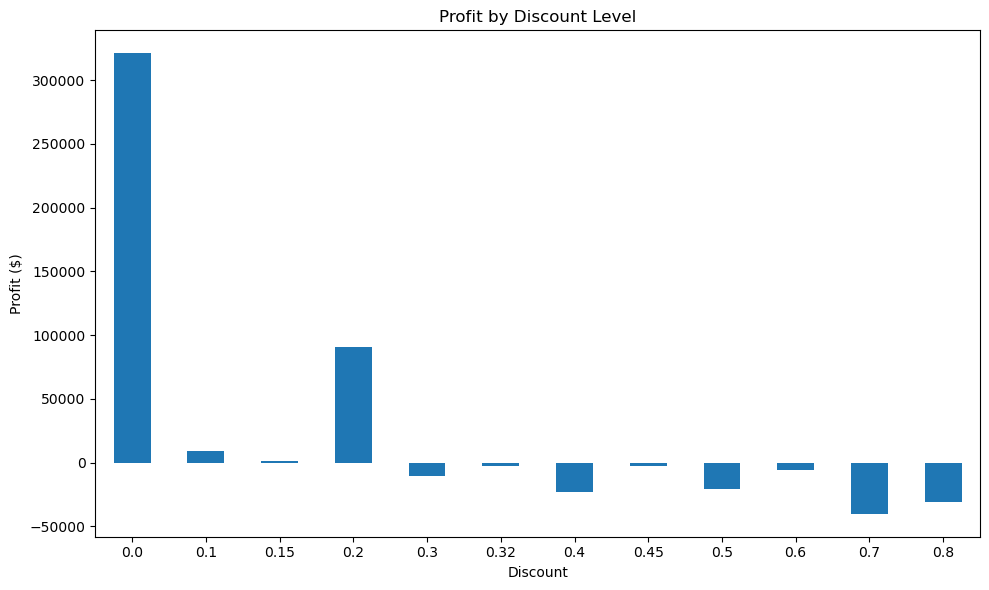

In [64]:
discount_analysis["Profit"].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [66]:
category_discount = df.groupby("Category").agg(
    Average_Discount=("Discount", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

category_discount["Profit_Margin (%)"] = (
    category_discount["Total_Profit"] /
    category_discount["Total_Sales"] * 100
).round(2)

category_discount

,Average_Discount,Total_Sales,Total_Profit,Profit_Margin (%)
Category,,,,
Furniture,0.173923,741999.7953,18451.2728,2.49
Office Supplies,0.157285,719047.0320,122490.8008,17.04
Technology,0.132323,836154.0330,145454.9481,17.40


In [68]:
furniture_analysis = df[df["Category"] == "Furniture"].groupby("Sub-Category").agg(
    Average_Discount=("Discount", "mean"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

furniture_analysis["Profit_Margin (%)"] = (
    furniture_analysis["Profit"] / furniture_analysis["Sales"] * 100
).round(2)

furniture_analysis.sort_values("Profit", ascending=True)

,Average_Discount,Sales,Profit,Profit_Margin (%)
Sub-Category,,,,
Tables,0.261285,206965.5320,-17725.4811,-8.56
Bookcases,0.211140,114879.9963,-3472.5560,-3.02
Furnishings,0.138349,91705.1640,13059.1436,14.24
Chairs,0.170178,328449.1030,26590.1663,8.10


# 8. Sales and Profit Trends

In [70]:
monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.head()

,Sales,Profit
Order Date,,
2014-01,14236.895,2450.1907
2014-02,4519.892,862.3084
2014-03,55691.009,498.7299
2014-04,28295.345,3488.8352
2014-05,23648.287,2738.7096


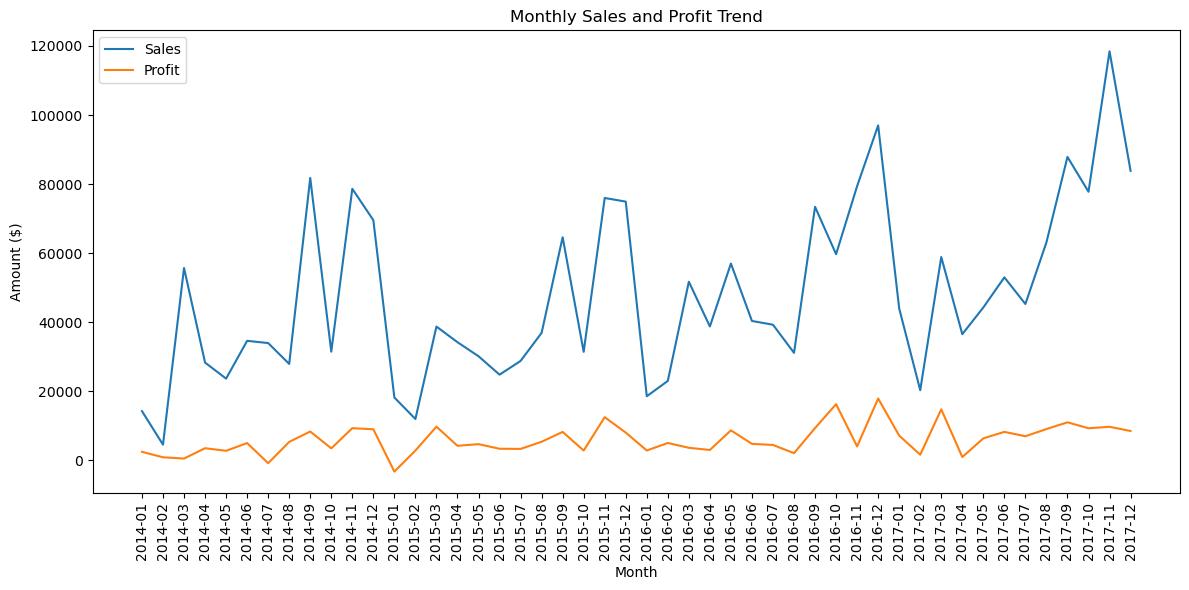

In [72]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_sales.index, monthly_sales["Sales"], label="Sales")
plt.plot(monthly_sales.index, monthly_sales["Profit"], label="Profit")

plt.title("Monthly Sales and Profit Trend")
plt.xlabel("Month")
plt.ylabel("Amount ($)")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

In [74]:
yearly_analysis = df.groupby(
    df["Order Date"].dt.year
).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)

yearly_analysis["Profit Margin (%)"] = (
    yearly_analysis["Profit"] / yearly_analysis["Sales"] * 100
).round(2)

yearly_analysis

,Sales,Profit,Orders,Profit Margin (%)
Order Date,,,,
2014,484247.4981,49543.9741,969,10.23
2015,470532.5090,61618.6037,1038,13.10
2016,609205.5980,81795.1743,1315,13.43
2017,733215.2552,93439.2696,1687,12.74


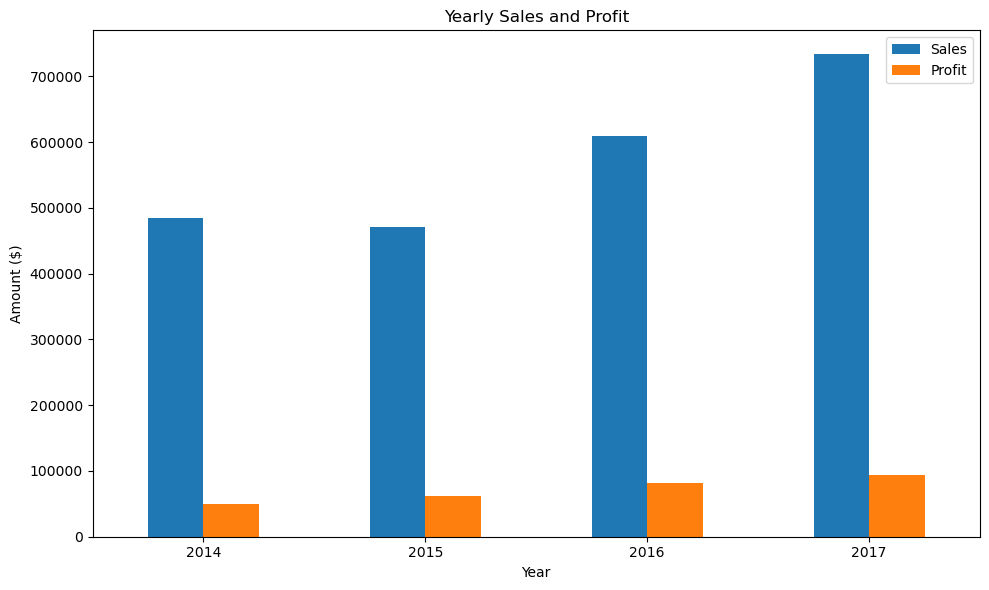

In [76]:
yearly_analysis[["Sales", "Profit"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Yearly Sales and Profit")
plt.xlabel("Year")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 9. Regional Analysis

In [78]:
region_analysis = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)

region_analysis["Profit Margin (%)"] = (
    region_analysis["Profit"] / region_analysis["Sales"] * 100
).round(2)

region_analysis.sort_values("Sales", ascending=False)

,Sales,Profit,Orders,Profit Margin (%)
Region,,,,
West,725457.8245,108418.4489,1611,14.94
East,678781.2400,91522.7800,1401,13.48
Central,501239.8908,39706.3625,1175,7.92
South,391721.9050,46749.4303,822,11.93


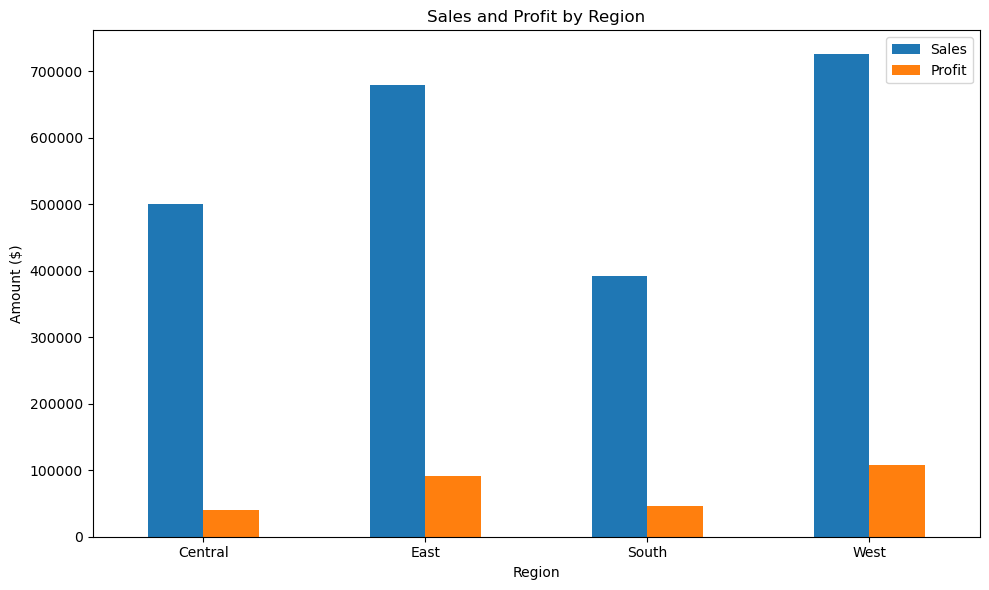

In [80]:
region_analysis[["Sales", "Profit"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 10. Customer Segment Analysis

In [82]:
segment_analysis = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Customers=("Customer ID", "nunique")
)

segment_analysis["Profit Margin (%)"] = (
    segment_analysis["Profit"] /
    segment_analysis["Sales"] * 100
).round(2)

segment_analysis.sort_values("Sales", ascending=False)

,Sales,Profit,Orders,Customers,Profit Margin (%)
Segment,,,,,
Consumer,1.161401e+06,134119.2092,2586,409,11.55
Corporate,7.061464e+05,91979.1340,1514,236,13.03
Home Office,4.296531e+05,60298.6785,909,148,14.03


# 11. Product Performance Analysis

In [84]:
top_products = df.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum")
)

top_products_sales = top_products.sort_values(
    "Sales", ascending=False
).head(10)

top_products_sales

,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03,6
HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14,39
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03,12
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27


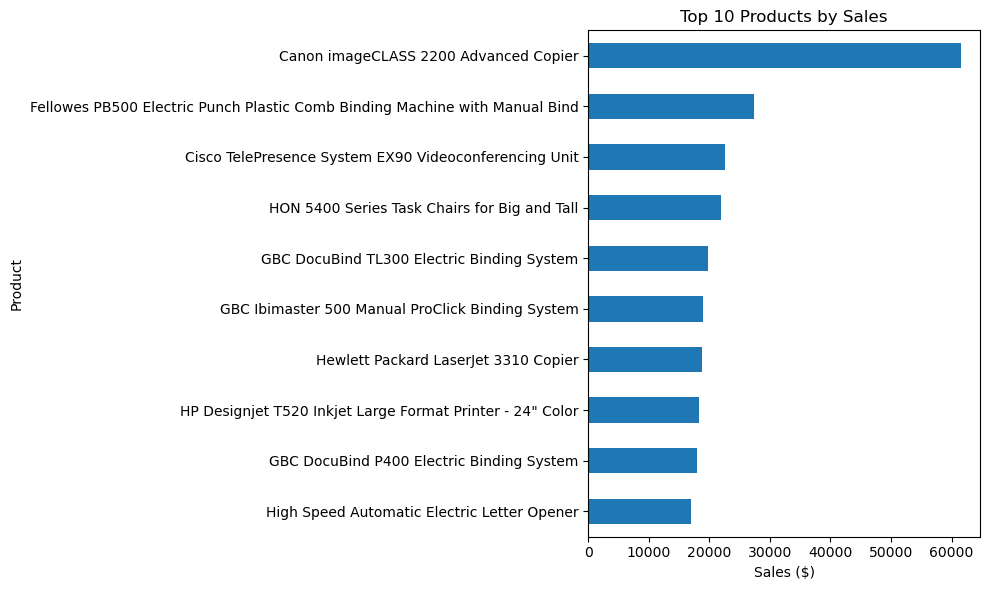

In [86]:
top_products_sales["Sales"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [88]:
top_profit_products = top_products.sort_values(
    "Profit", ascending=False
).head(10)

top_profit_products

,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38
Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820,24
Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13


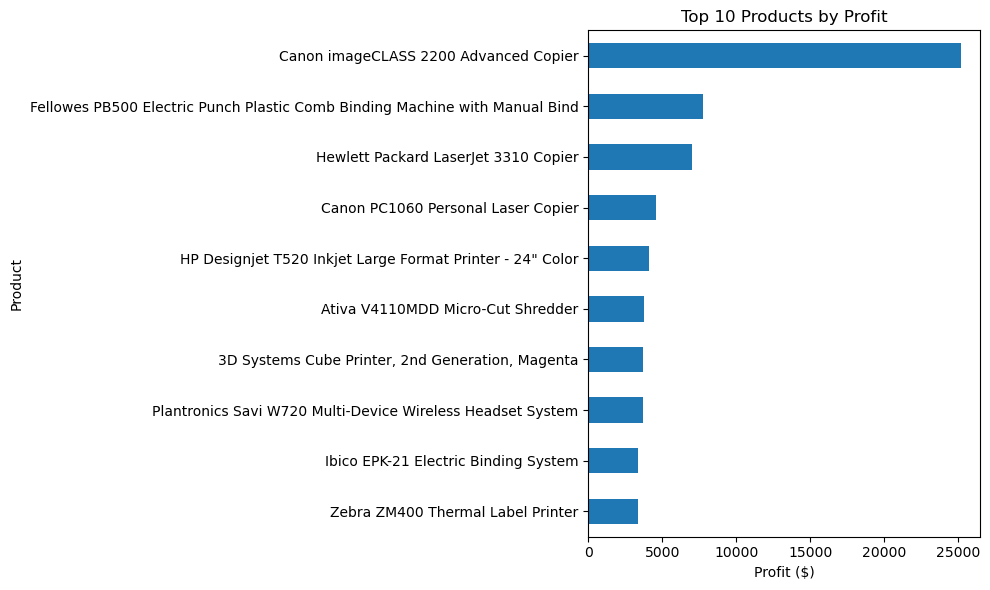

In [90]:
top_profit_products["Profit"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Profit")
plt.xlabel("Profit ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [92]:
bottom_profit_products = top_products.sort_values(
    "Profit", ascending=True
).head(10)

bottom_profit_products

,Sales,Profit,Quantity
Product Name,,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22
Balt Solid Wood Round Tables,6518.754,-1201.0581,19


In [94]:
loss_making_products = top_products[
    (top_products["Sales"] > 10000) &
    (top_products["Profit"] < 0)
].sort_values("Sales", ascending=False)

loss_making_products

,Sales,Profit,Quantity
Product Name,,,
Cisco TelePresence System EX90 Videoconferencing Unit,22638.4800,-1811.0784,6
GBC DocuBind P400 Electric Binding System,17965.0680,-1878.1662,27
High Speed Automatic Electric Letter Opener,17030.3120,-262.0048,11
Lexmark MX611dhe Monochrome Laser Printer,16829.9010,-4589.9730,18
Martin Yale Chadless Opener Electric Letter Opener,16656.2000,-1299.1836,22
"Riverside Palais Royal Lawyers Bookcase, Royale Cherry Finish",15610.9656,-669.5448,24
Bretford Rectangular Conference Table Tops,12995.2915,-327.2331,46
Cubify CubeX 3D Printer Double Head Print,11099.9630,-8879.9704,9


In [96]:
loss_making_products["Profit Margin (%)"] = (
    loss_making_products["Profit"] /
    loss_making_products["Sales"] * 100
).round(2)

loss_making_products

,Sales,Profit,Quantity,Profit Margin (%)
Product Name,,,,
Cisco TelePresence System EX90 Videoconferencing Unit,22638.4800,-1811.0784,6,-8.00
GBC DocuBind P400 Electric Binding System,17965.0680,-1878.1662,27,-10.45
High Speed Automatic Electric Letter Opener,17030.3120,-262.0048,11,-1.54
Lexmark MX611dhe Monochrome Laser Printer,16829.9010,-4589.9730,18,-27.27
Martin Yale Chadless Opener Electric Letter Opener,16656.2000,-1299.1836,22,-7.80
"Riverside Palais Royal Lawyers Bookcase, Royale Cherry Finish",15610.9656,-669.5448,24,-4.29
Bretford Rectangular Conference Table Tops,12995.2915,-327.2331,46,-2.52
Cubify CubeX 3D Printer Double Head Print,11099.9630,-8879.9704,9,-80.00


# 12. Shipping Analysis

In [98]:
shipping_analysis = df.groupby("Ship Mode").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Avg_Shipping_Days=("Shipping Days", "mean")
)

shipping_analysis["Profit Margin (%)"] = (
    shipping_analysis["Profit"] /
    shipping_analysis["Sales"] * 100
).round(2)

shipping_analysis

,Sales,Profit,Orders,Avg_Shipping_Days,Profit Margin (%)
Ship Mode,,,,,
First Class,3.514284e+05,48969.8399,787,2.182705,13.93
Same Day,1.283631e+05,15891.7589,264,0.044199,12.38
Second Class,4.591936e+05,57446.6354,964,3.238046,12.51
Standard Class,1.358216e+06,164088.7875,2994,5.006535,12.08


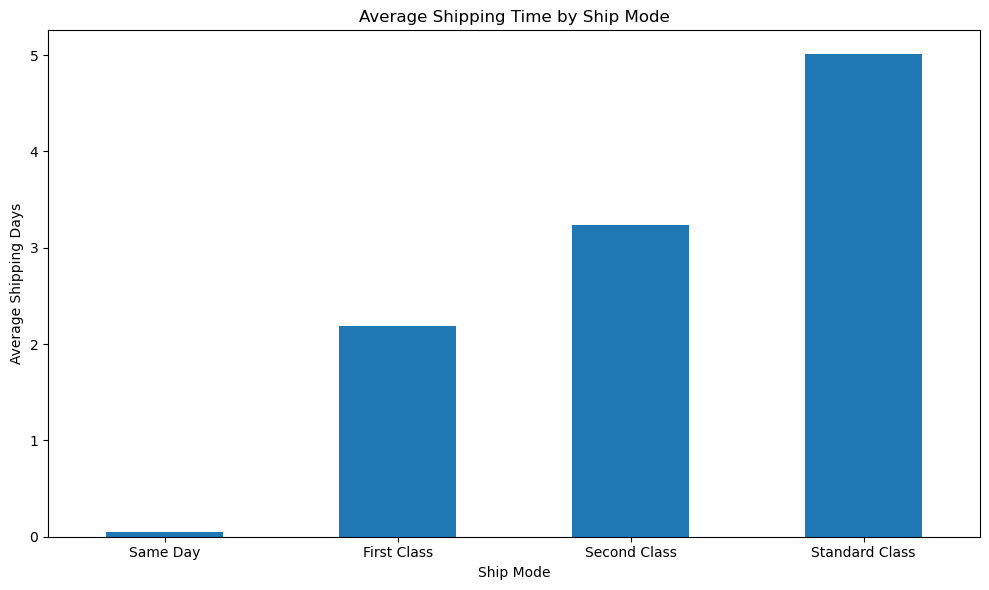

In [100]:
shipping_analysis["Avg_Shipping_Days"].sort_values().plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Shipping Time by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 13. Customer Profitability Analysis

In [102]:

customer_analysis = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)

customer_analysis["Profit Margin (%)"] = (
    customer_analysis["Profit"] /
    customer_analysis["Sales"] * 100
).round(2)

top_customers = customer_analysis.sort_values(
    "Sales", ascending=False
).head(10)

top_customers

,,Sales,Profit,Orders,Profit Margin (%)
Customer ID,Customer Name,,,,
SM-20320,Sean Miller,25043.050,-1980.7393,5,-7.91
TC-20980,Tamara Chand,19052.218,8981.3239,5,47.14
RB-19360,Raymond Buch,15117.339,6976.0959,6,46.15
TA-21385,Tom Ashbrook,14595.620,4703.7883,4,32.23
AB-10105,Adrian Barton,14473.571,5444.8055,10,37.62
KL-16645,Ken Lonsdale,14175.229,806.8550,12,5.69
SC-20095,Sanjit Chand,14142.334,5757.4119,9,40.71
HL-15040,Hunter Lopez,12873.298,5622.4292,6,43.68
SE-20110,Sanjit Engle,12209.438,2650.6769,11,21.71


In [104]:
loss_making_customers = customer_analysis[
    (customer_analysis["Sales"] > 5000) &
    (customer_analysis["Profit"] < 0)
].sort_values("Sales", ascending=False)

loss_making_customers.head(10)

,,Sales,Profit,Orders,Profit Margin (%)
Customer ID,Customer Name,,,,
SM-20320,Sean Miller,25043.050,-1980.7393,5,-7.91
BM-11140,Becky Martin,11789.630,-1659.9581,4,-14.08
GT-14635,Grant Thornton,9351.212,-4108.6589,3,-43.94
PF-19120,Peter Fuller,9062.864,-614.2943,4,-6.78
NF-18385,Natalie Fritzler,8322.826,-1695.9714,7,-20.38
SB-20290,Sean Braxton,8057.891,-2082.7451,7,-25.85
ZC-21910,Zuschuss Carroll,8025.707,-1032.1490,13,-12.86
JH-15985,Joseph Holt,7954.998,-644.6982,6,-8.10
JA-15970,Joseph Airdo,6491.026,-819.4217,8,-12.62


In [106]:
loss_making_customers["Profit Margin (%)"] = (
    loss_making_customers["Profit"] /
    loss_making_customers["Sales"] * 100
).round(2)

loss_making_customers.head(10)

,,Sales,Profit,Orders,Profit Margin (%)
Customer ID,Customer Name,,,,
SM-20320,Sean Miller,25043.050,-1980.7393,5,-7.91
BM-11140,Becky Martin,11789.630,-1659.9581,4,-14.08
GT-14635,Grant Thornton,9351.212,-4108.6589,3,-43.94
PF-19120,Peter Fuller,9062.864,-614.2943,4,-6.78
NF-18385,Natalie Fritzler,8322.826,-1695.9714,7,-20.38
SB-20290,Sean Braxton,8057.891,-2082.7451,7,-25.85
ZC-21910,Zuschuss Carroll,8025.707,-1032.1490,13,-12.86
JH-15985,Joseph Holt,7954.998,-644.6982,6,-8.10
JA-15970,Joseph Airdo,6491.026,-819.4217,8,-12.62


# 14. State Analysis

In [108]:
state_analysis = df.groupby("State").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)

state_analysis["Profit Margin (%)"] = (
    state_analysis["Profit"] / state_analysis["Sales"] * 100
).round(2)

top_states = state_analysis.sort_values(
    "Sales", ascending=False
).head(10)

top_states

,Sales,Profit,Orders,Profit Margin (%)
State,,,,
California,457687.6315,76381.3871,1021,16.69
New York,310876.2710,74038.5486,562,23.82
Texas,170188.0458,-25729.3563,487,-15.12
Washington,138641.2700,33402.6517,256,24.09
Pennsylvania,116511.9140,-15559.9603,288,-13.35
Florida,89473.7080,-3399.3017,200,-3.80
Illinois,80166.1010,-12607.8870,276,-15.73
Ohio,78258.1360,-16971.3766,236,-21.69
Michigan,76269.6140,24463.1876,117,32.07


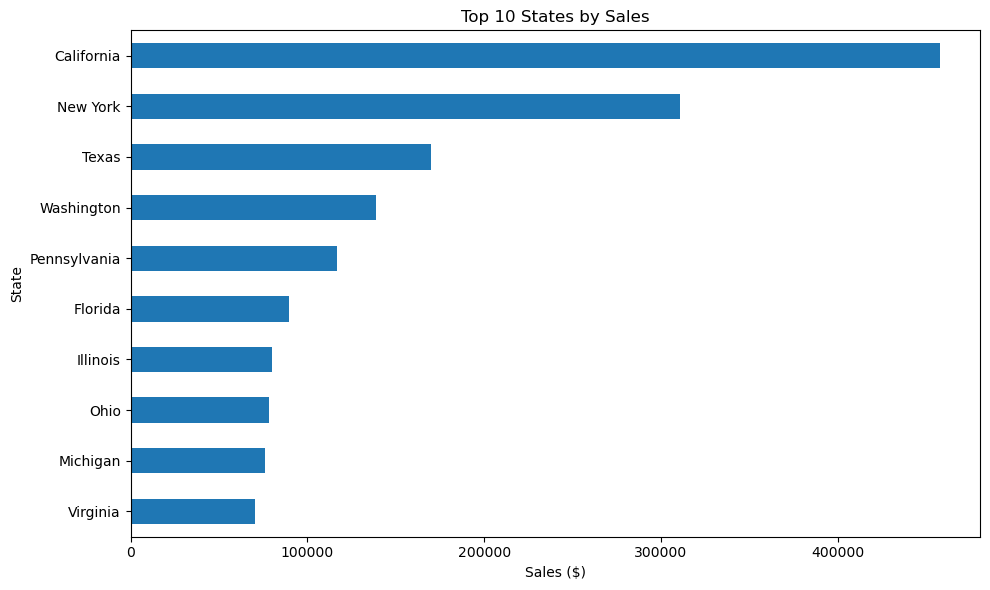

In [110]:
top_states["Sales"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 States by Sales")
plt.xlabel("Sales ($)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

# 15. Correlation Analysis

In [112]:
correlation = df[[
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping Days"
]].corr()

correlation

,Sales,Quantity,Discount,Profit,Shipping Days
Sales,1.000000,0.200795,-0.028190,0.479064,-0.007354
Quantity,0.200795,1.000000,0.008623,0.066253,0.018298
Discount,-0.028190,0.008623,1.000000,-0.219487,0.000408
Profit,0.479064,0.066253,-0.219487,1.000000,-0.004649
Shipping Days,-0.007354,0.018298,0.000408,-0.004649,1.000000


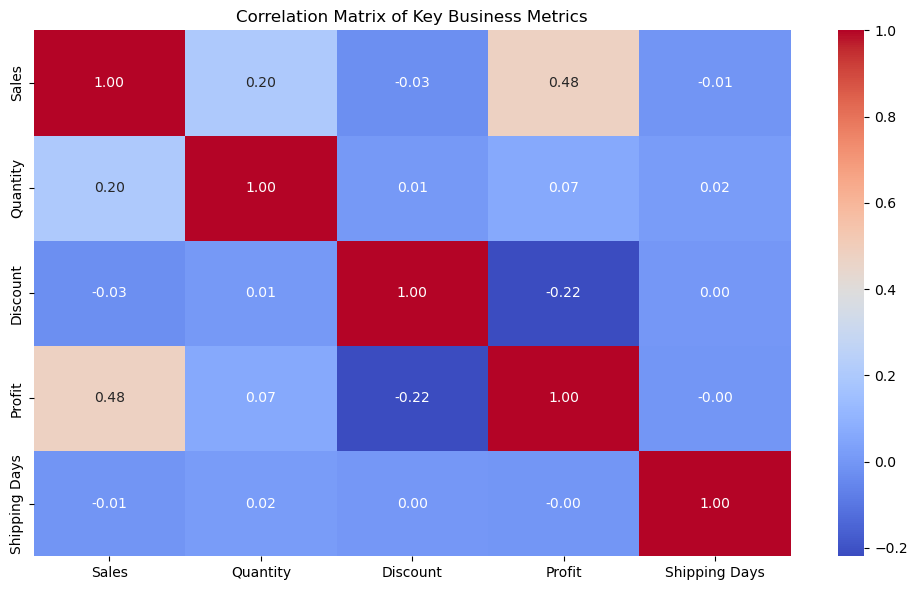

In [114]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Key Business Metrics")
plt.tight_layout()
plt.show()

# 16. Key Business Insights

1. The business generated approximately **$2.30 million in sales** and **$286.40K in profit**, with an overall profit margin of **12.47%**.

2. **Technology** generated the highest sales and profit among the three categories, while **Furniture** had a relatively low profit margin of only **2.49%**.

3. **Tables** were a major loss-making sub-category, generating approximately **$207K in sales but a loss of $17.73K**.

4. Higher discount levels were associated with lower profitability. Discounts of **30% or more showed negative overall profit** in the dataset.

5. **West** was the strongest region by profit, while **Central** had a relatively low profit margin of **7.92%**.

6. **2017** recorded the highest annual sales and profit, showing overall business growth over the analyzed period.

7. Several products generated high sales but negative profit, showing that **high revenue does not always mean high profitability**.

8. Some customers also generated significant sales while producing negative profit, highlighting the importance of customer-level profitability analysis.

9. The correlation analysis showed a **moderate positive relationship between Sales and Profit (0.48)**.

10. **Discount and Profit showed a negative correlation (-0.22)**, while Shipping Days had almost no correlation with Profit.

# 17. Business Recommendations

- Review high discount levels, especially discounts of 30% or more, to protect profit margins.
- Reassess pricing and discount strategies for loss-making sub-categories such as Tables and Bookcases.
- Investigate products and customers that generate high sales but negative profit.
- Focus on profitable categories such as Technology and profitable sub-categories such as Copiers and Paper.
- Investigate the relatively low profitability of the Central region.
- Monitor profitability alongside sales when evaluating products, customers, and regions.
- Use customer-level profitability analysis to identify customers that may require pricing or discount adjustments.

# 18. Conclusion

This project analyzed Superstore sales data to understand sales performance, profitability, customers, products, regions, discounts, and shipping.

The analysis shows that increasing sales alone does not guarantee higher profitability. Discount levels, product selection, customer profitability, and regional performance have an important impact on business results.

The findings can help the business improve pricing and discount strategies, reduce losses from unprofitable products and customers, and focus on areas that provide stronger profit margins.

Overall, the project demonstrates how Python-based data analysis can transform raw sales data into meaningful business insights and actionable recommendations.

In [150]:
df.to_csv("Superstore_Cleaned.csv", index=False)